# Task 3 - Cognitive load and the data-ink ratio

Data: `car_crashes.csv` (51 rows: 50 states + DC) and `tips.csv`.

Units note: `total` is "drivers involved in fatal collisions per billion miles"; the other columns are percentages or
dollars. Only `total` is plotted. Putting the columns on one axis would be a Week 1 mistake, not a load problem.

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from IPython.display import Markdown

SAVE = dict(dpi=300, bbox_inches="tight")
BLUE = "#4c72b0"
Y_LABEL = "Drivers in fatal collisions per billion miles"

cc = pd.read_csv(r"C:\Users\Nas Graphy\Downloads\Data visdualtion\Week 2\car_crashes.csv")
tips = pd.read_csv(r"C:\Users\Nas Graphy\Downloads\Data visdualtion\Week 2\tips.csv")
N = len(cc)
print(cc.shape, tips.shape)


def rainbow(n):
    return matplotlib.colormaps["hsv"](np.linspace(0, 1, n, endpoint=False))

(51, 8) (244, 7)


## 1. Build an overloaded chart on purpose
Every bar a different colour, 51 rotated labels, heavy gridlines both ways, a box frame, a 51-entry legend,
a drop shadow, and a title that names the axes.

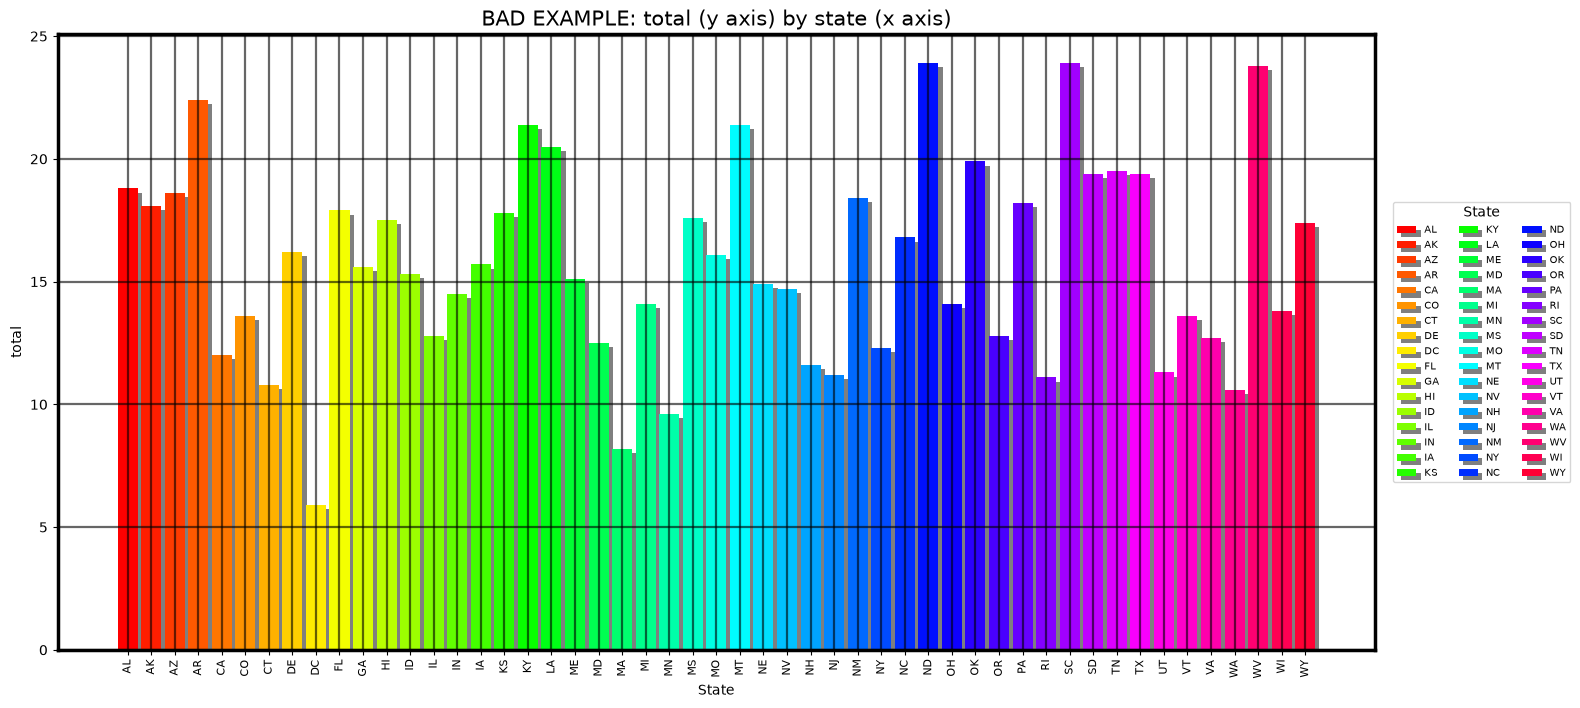

In [2]:
def make_bad_example():
    fig, ax = plt.subplots(figsize=(17, 8))
    x = np.arange(N)
    bars = ax.bar(x, cc["total"], color=rainbow(N), width=0.85)

    for b in bars:  # drop shadow on every bar
        b.set_path_effects([pe.withSimplePatchShadow(offset=(3, -3), shadow_rgbFace="black", alpha=0.5)])

    ax.set_xticks(x)
    ax.set_xticklabels(cc["abbrev"], rotation=90, fontsize=8)
    ax.grid(True, which="major", axis="both", linewidth=1.6, color="black", alpha=0.6)  # heavy, both ways
    for s in ax.spines.values():
        s.set_linewidth(2.5)  # box frame
    legend = ax.legend(bars, cc["abbrev"], ncol=3, loc="center left", bbox_to_anchor=(1.01, 0.5),
                       fontsize=7, title="State")
    ax.set_xlabel("State")
    ax.set_ylabel("total")
    ax.set_title("BAD EXAMPLE: total (y axis) by state (x axis)", fontsize=15)
    fig.savefig("task3_bad_example.png", **SAVE)
    return fig, ax, bars, legend


bad_fig, bad_ax, bad_bars, bad_legend = make_bad_example()
plt.show()

## 2. Count the load
Every element, classified as intrinsic / extraneous / germane, then the data-ink estimate **with the working shown**.
(Counted from the actual chart object, so the numbers are not typed in by hand.)

In [3]:
def audit_bad_example(fig, ax, bars, legend):
    fig.canvas.draw()  # make sure ticks exist before counting them
    ylo, yhi = ax.get_ylim()
    n_y_ticks = len([t for t in ax.get_yticks() if ylo <= t <= yhi])
    n_x_ticks = len(ax.get_xticks())

    # element, how many marks, class, why
    rows = [
        ("Bars (height = total)", len(bars), "intrinsic", "this IS the data: 51 numbers"),
        ("Bar drop shadows", len(bars), "extraneous", "decoration, encodes nothing"),
        ("51 different bar colours", 0, "extraneous", "x position already says which state; colour repeats it (attribute of the bars, no extra marks counted)"),
        ("State labels on x axis (rotated 90)", n_x_ticks, "extraneous", "needed information, but rotated and tiny so the reader must tilt their head and squint"),
        ("x tick marks", n_x_ticks, "extraneous", "one per bar, adds nothing the labels don't"),
        ("Vertical gridlines", n_x_ticks, "extraneous", "there is nothing to read off along x"),
        ("Horizontal gridlines", n_y_ticks, "germane", "help turn bar height into a number, but far too heavy here"),
        ("y tick labels", n_y_ticks, "germane", "let the reader decode the value"),
        ("y tick marks", n_y_ticks, "extraneous", "gridlines already do this job"),
        ("Box frame (4 spines)", 4, "extraneous", "borders hold nothing"),
        ("Legend swatches", len(bars), "extraneous", "colour -> state lookup that x labels already provide"),
        ("Legend text entries", len(bars), "extraneous", "51 items to hold in working memory"),
        ("Legend title", 1, "extraneous", ""),
        ("Chart title (names the axes)", 1, "extraneous", "says what the axes already say"),
        ("Axis labels (2)", 2, "germane", "units / meaning for the reader (the y one is too terse: 'total')"),
    ]
    total_marks = sum(r[1] for r in rows)
    encoding_marks = len(bars)
    ratio = encoding_marks / total_marks

    short = ["bars", "shadows", "x labels", "x ticks", "x grid", "y grid", "y labels", "y ticks",
             "frame", "legend swatches", "legend text", "legend title", "title", "axis labels"]
    counted = [r for r in rows if r[1]]
    sum_text = " + ".join(f"{r[1]} {name}" for r, name in zip(counted, short))

    lines = ["| Element | Marks | Load type | Why |", "|---|---|---|---|"]
    for el, n, kind, why in rows:
        lines.append(f"| {el} | {n if n else '-'} | {kind} | {why} |")
    lines += [
        "",
        "### Data-ink estimate (marks counted, not ink area)",
        f"- Marks that encode a number: the {encoding_marks} bars (one number each).",
        f"- All marks: {sum_text} = {total_marks}.",
        f"- Data-ink ratio = {encoding_marks} / {total_marks} = **{ratio:.2f}**.",
        f"- If I also count the {n_y_ticks} y tick labels as 'encoding' (they let you decode the bars) "
        f"it is {encoding_marks + n_y_ticks} / {total_marks} = {(encoding_marks + n_y_ticks) / total_marks:.2f}. "
        "Either way most of the marks carry no data.",
        "- This counts marks, not ink area, so the shadows, thick frame and heavy grid are underweighted. It is a rough estimate.",
    ]
    text = "\n".join(lines)
    with open("task3_load_audit.md", "w") as f:
        f.write(text)
    return text


Markdown(audit_bad_example(bad_fig, bad_ax, bad_bars, bad_legend))

| Element | Marks | Load type | Why |
|---|---|---|---|
| Bars (height = total) | 51 | intrinsic | this IS the data: 51 numbers |
| Bar drop shadows | 51 | extraneous | decoration, encodes nothing |
| 51 different bar colours | - | extraneous | x position already says which state; colour repeats it (attribute of the bars, no extra marks counted) |
| State labels on x axis (rotated 90) | 51 | extraneous | needed information, but rotated and tiny so the reader must tilt their head and squint |
| x tick marks | 51 | extraneous | one per bar, adds nothing the labels don't |
| Vertical gridlines | 51 | extraneous | there is nothing to read off along x |
| Horizontal gridlines | 6 | germane | help turn bar height into a number, but far too heavy here |
| y tick labels | 6 | germane | let the reader decode the value |
| y tick marks | 6 | extraneous | gridlines already do this job |
| Box frame (4 spines) | 4 | extraneous | borders hold nothing |
| Legend swatches | 51 | extraneous | colour -> state lookup that x labels already provide |
| Legend text entries | 51 | extraneous | 51 items to hold in working memory |
| Legend title | 1 | extraneous |  |
| Chart title (names the axes) | 1 | extraneous | says what the axes already say |
| Axis labels (2) | 2 | germane | units / meaning for the reader (the y one is too terse: 'total') |

### Data-ink estimate (marks counted, not ink area)
- Marks that encode a number: the 51 bars (one number each).
- All marks: 51 bars + 51 shadows + 51 x labels + 51 x ticks + 51 x grid + 6 y grid + 6 y labels + 6 y ticks + 4 frame + 51 legend swatches + 51 legend text + 1 legend title + 1 title + 2 axis labels = 383.
- Data-ink ratio = 51 / 383 = **0.13**.
- If I also count the 6 y tick labels as 'encoding' (they let you decode the bars) it is 57 / 383 = 0.15. Either way most of the marks carry no data.
- This counts marks, not ink area, so the shadows, thick frame and heavy grid are underweighted. It is a rough estimate.

## 3. Strip it down, one step at a time
Five panels, same data, lighter each time. My order: legend, then frame + one gridline axis, then single hue, then sort, then label only what matters.

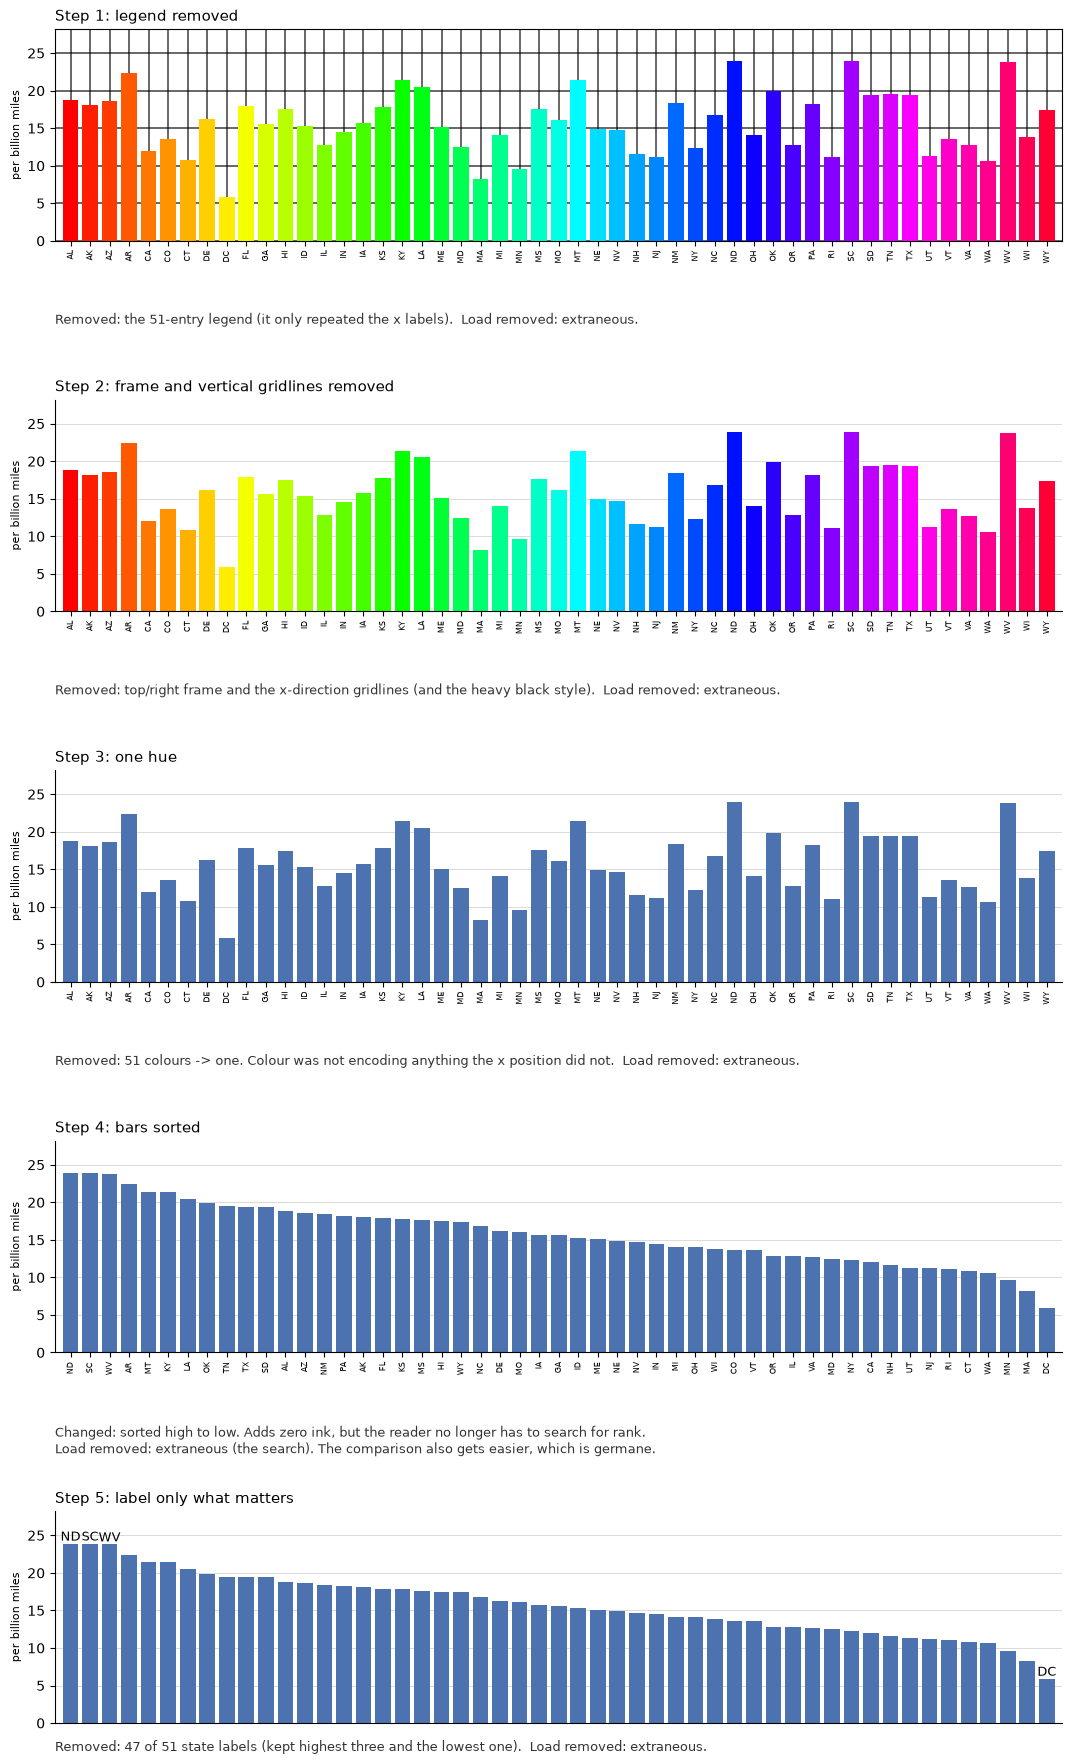

In [4]:
STEPS = [
    dict(title="Step 1: legend removed", multi=True, grid_x=True, grid_y=True, frame=True,
         sort=False, labels="all", heavy=True,
         caption="Removed: the 51-entry legend (it only repeated the x labels).  Load removed: extraneous."),
    dict(title="Step 2: frame and vertical gridlines removed", multi=True, grid_x=False, grid_y=True,
         frame=False, sort=False, labels="all", heavy=False,
         caption="Removed: top/right frame and the x-direction gridlines (and the heavy black style).  Load removed: extraneous."),
    dict(title="Step 3: one hue", multi=False, grid_x=False, grid_y=True, frame=False,
         sort=False, labels="all", heavy=False,
         caption="Removed: 51 colours -> one. Colour was not encoding anything the x position did not.  Load removed: extraneous."),
    dict(title="Step 4: bars sorted", multi=False, grid_x=False, grid_y=True, frame=False,
         sort=True, labels="all", heavy=False,
         caption="Changed: sorted high to low. Adds zero ink, but the reader no longer has to search for rank.\n"
                 "Load removed: extraneous (the search). The comparison also gets easier, which is germane."),
    dict(title="Step 5: label only what matters", multi=False, grid_x=False, grid_y=True, frame=False,
         sort=True, labels="key", heavy=False,
         caption="Removed: 47 of 51 state labels (kept highest three and the lowest one).  Load removed: extraneous."),
]


def bar_panel(ax, step):
    d = cc.sort_values("total", ascending=False) if step["sort"] else cc
    x = np.arange(len(d))
    ax.bar(x, d["total"], color=rainbow(len(d)) if step["multi"] else BLUE, width=0.8)
    ax.set_axisbelow(True)
    ax.set_xlim(-0.8, len(d) - 0.2)
    ax.set_ylim(0, cc["total"].max() * 1.18)
    ax.set_ylabel("per billion miles", fontsize=8)

    if step["grid_y"]:
        ax.grid(True, axis="y", linewidth=1.4 if step["heavy"] else 0.5,
                color="black" if step["heavy"] else "0.8", alpha=0.6 if step["heavy"] else 1)
    if step["grid_x"]:
        ax.grid(True, axis="x", linewidth=1.4, color="black", alpha=0.6)

    if step["labels"] == "all":
        ax.set_xticks(x)
        ax.set_xticklabels(d["abbrev"], rotation=90, fontsize=6)
        caption_y = -0.34
    else:
        ax.set_xticks([])
        top = list(range(3)) + [len(d) - 1]  # sorted, so first three and the last one
        for i in top:
            ax.text(i, d["total"].iloc[i] + 0.4, d["abbrev"].iloc[i], ha="center", fontsize=9)
        caption_y = -0.08

    if not step["frame"]:
        ax.spines[["top", "right"]].set_visible(False)
    ax.set_title(step["title"], loc="left", fontsize=11)
    ax.text(0, caption_y, step["caption"], transform=ax.transAxes, fontsize=9, va="top", color="0.2")


fig, axes = plt.subplots(5, 1, figsize=(13, 22))
for ax, step in zip(axes, STEPS):
    bar_panel(ax, step)
fig.subplots_adjust(hspace=0.75)
fig.savefig("task3_five_steps.png", **SAVE)
plt.show()

The Five-Stage Decluttering Framework**

* **Methodology:** A disciplined visual progression demonstrating how the cluttered chart from Image 5 is transformed into an executive-grade visual deliverable.


* **Detailed Breakdown:**
* **Step 1 (Legend Removed):** Deletes the 51-entry color legend. Immediately recovers horizontal real estate and eliminates useless back-and-forth eye tracking.


* **Step 2 (Frame & Vertical Gridlines Removed):** Strips the heavy black outer border and all vertical gridlines. Faint horizontal lines remain to support accurate value estimation without visual clutter.


* **Step 3 (One Hue Applied):** Collapses the chaotic rainbow palette into a single, cohesive steel-blue tone. Color now correctly reflects that all bars belong to the same metric.


* **Step 4 (Bars Sorted):** Transforms the arbitrary alphabetical sequence into a ranked descending order. Readers can now instantly identify rankings, distribution shape, and relative performance without manual searching.


* **Step 5 (Label Only What Matters):** Removes 47 crowded state labels along the axis, directly annotating only the top 3 highest-risk states (North Dakota, South Carolina, West Virginia) and the lowest (District of Columbia).




* **Core Takeaway:** Decluttering is not just an aesthetic clean-up; it systematically removes extraneous cognitive friction so the data story emerges clearly.




**Notice:** sorting the bars (step 4) is the single highest-value edit and it adds no ink at all.

## 4. Respect the 4 +/- 1 limit
Working memory holds about four chunks, so I group the 51 states into the four US Census regions (DC counts as South).
Each state is a grey dot, the black line is the regional median, and only the highest state in each region is named.

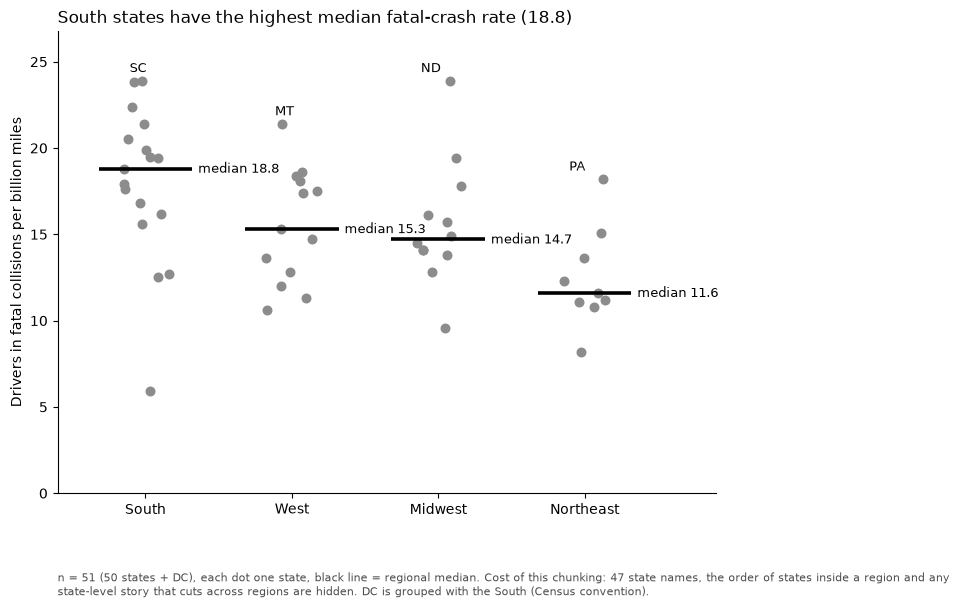

In [5]:
REGIONS = {
    "Northeast": "CT ME MA NH RI VT NJ NY PA",
    "Midwest": "IL IN MI OH WI IA KS MN MO NE ND SD",
    "South": "DE DC FL GA MD NC SC VA WV AL KY MS TN AR LA OK TX",
    "West": "AZ CO ID MT NV NM UT WY AK CA HI OR WA",
}
ABBREV_TO_REGION = {a: r for r, s in REGIONS.items() for a in s.split()}

d = cc.copy()
d["region"] = d["abbrev"].map(ABBREV_TO_REGION)
missing = d[d["region"].isna()]["abbrev"].tolist()
assert not missing, f"these abbreviations have no region, fix REGIONS: {missing}"

medians = d.groupby("region")["total"].median().sort_values(ascending=False)
order = list(medians.index)
rng = np.random.default_rng(3)  # only for the sideways jitter of the dots

fig, ax = plt.subplots(figsize=(8.5, 6))
for i, region in enumerate(order):
    part = d[d["region"] == region]
    xs = i + rng.uniform(-0.18, 0.18, len(part))
    ax.scatter(xs, part["total"], s=38, color="0.55", zorder=2)
    ax.hlines(medians[region], i - 0.32, i + 0.32, color="black", linewidth=2.6, zorder=3)
    ax.text(i + 0.36, medians[region], f"median {medians[region]:.1f}", va="center", fontsize=9)
    worst = part.loc[part["total"].idxmax()]  # name just the highest state in each chunk
    ax.text(i - 0.05, worst["total"] + 0.5, worst["abbrev"], ha="center", fontsize=9)

ax.set_xticks(range(len(order)))
ax.set_xticklabels(order)
ax.set_xlim(-0.6, len(order) - 0.1)
ax.set_ylim(0, d["total"].max() * 1.12)
ax.set_ylabel(Y_LABEL)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title(f"{order[0]} states have the highest median fatal-crash rate ({medians.iloc[0]:.1f})",
             loc="left", fontsize=12)
fig.text(0.125, -0.02,
         f"n = {len(d)} (50 states + DC), each dot one state, black line = regional median. "
         "Cost of this chunking: 47 state names, the order of states inside a region and any\n"
         "state-level story that cuts across regions are hidden. DC is grouped with the South (Census convention).",
         fontsize=8, color="0.3", va="top")
fig.savefig("task3_chunked_regions.png", **SAVE)
plt.show()

Categorical Distribution & Contextual Benchmarking**

* **Dataset & Chart Style:** Strip plot / Jittered dot plot of drivers involved in fatal collisions per billion miles across 51 US jurisdictions (50 states + DC), chunked by US Census Region.


* **Detailed Breakdown:**
* **Regional Medians (Heavy Black Reference Lines):**
* **South:** Median crash rate is the nation's highest at **18.8**. South Carolina (SC, ~24.0) anchors the top tier.


* **West:** Median rate is **15.3**, with Montana (MT, ~21.4) identified as an elevated outlier.


* **Midwest:** Median rate is **14.7**, with North Dakota (ND, ~23.9) sitting well above the pack.


* **Northeast:** Lowest median rate across the nation at **11.6**, with Pennsylvania (PA, ~18.2) as a high outlier.




* **Perceptual Advantages:**
* Unlike a standard bar chart that would compress all data into a single average value per region, the jittered dot plot reveals distribution density, internal variance, and extreme values while maintaining a clean summary baseline.






* **Core Takeaway:** Combining raw distribution points with summary reference lines gives viewers both the big-picture trend and the underlying variance.

**Chunking I chose:** four Census regions (4 chunks, inside the 4 +/- 1 limit).
**What it costs:** 47 state names, the order of states inside a region, and any state-level pattern that cuts across
regions. DC is also placed in the South by convention.

## 5. Over-strip it

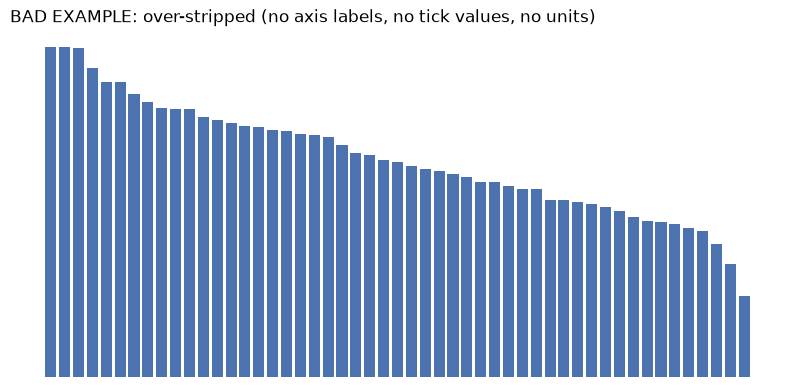

In [6]:
d = cc.sort_values("total", ascending=False)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(np.arange(len(d)), d["total"], color=BLUE, width=0.8)
ax.set_xticks([])
ax.set_yticks([])
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("BAD EXAMPLE: over-stripped (no axis labels, no tick values, no units)", loc="left", fontsize=12)
fig.savefig("task3_over_stripped.png", **SAVE)
plt.show()

Over-Stripping and Information Deprivation (Anti-Pattern)**

* **Theoretical Background:** Demonstrates the hazard of taking minimalism too far—where data-ink maximization degrades into **complete data starvation**.


* **Detailed Breakdown:**
* **Missing Structural Anchors:**
* The X-axis has no category names, ticks, or baseline reference.


* The Y-axis has no numerical values, scale intervals, baseline zero, or unit of measurement.


* The chart lacks a title, subtitle, or data source.




* **Interpretive Failure:** While the viewer can perceive a sorted Pareto-like decay curve, they have no idea whether this represents road fatalities, company revenue, machine failure rates, or customer churn. The chart is visually neat, but analytically useless.




* **Core Takeaway:** Minimalism should eliminate noise, never necessary context. Every chart must preserve readable axes, clear units, and descriptive labels.



## 6. The question: ink that lowers cognitive load (tips.csv)
Same scatter twice: tip against bill. Left has no reference line; right adds one 15% line, directly labelled.

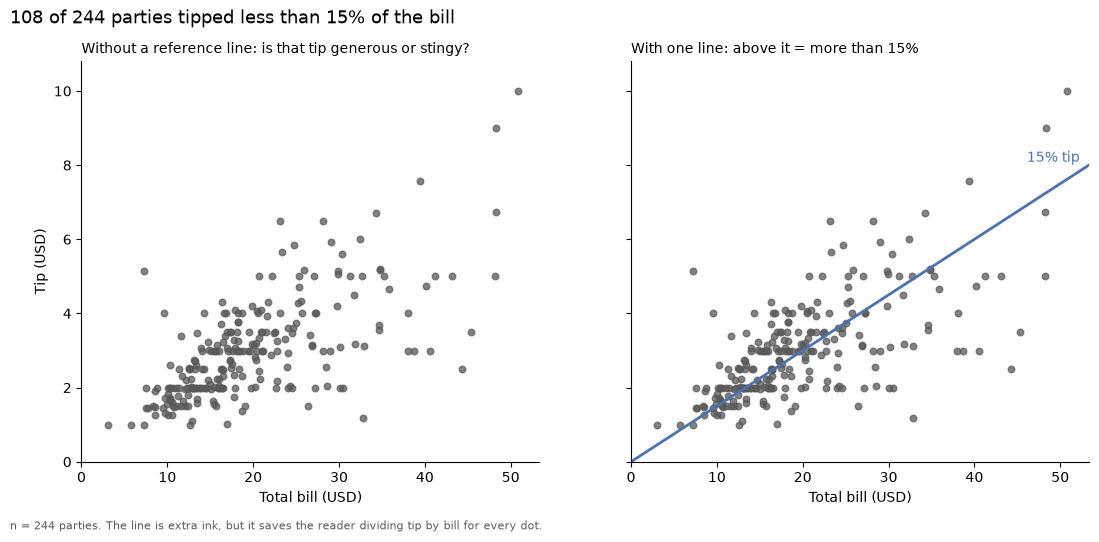

In [7]:
t = tips.copy()
t["pct"] = t["tip"] / t["total_bill"]
below = int((t["pct"] < 0.15).sum())
xmax = t["total_bill"].max() * 1.05
xs = np.array([0, xmax])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), sharex=True, sharey=True)
for ax in (ax1, ax2):
    ax.scatter(t["total_bill"], t["tip"], s=22, color="0.35", alpha=0.75)
    ax.set_xlabel("Total bill (USD)")
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlim(0, xmax)
    ax.set_ylim(0, t["tip"].max() * 1.08)
ax1.set_ylabel("Tip (USD)")
ax1.set_title("Without a reference line: is that tip generous or stingy?", loc="left", fontsize=10)

ax2.plot(xs, 0.15 * xs, color=BLUE, linewidth=2)
ax2.text(xmax * 0.98, 0.15 * xmax * 0.98 + 0.25, "15% tip", color=BLUE, ha="right", fontsize=10)
ax2.set_title("With one line: above it = more than 15%", loc="left", fontsize=10)

fig.suptitle(f"{below} of {len(t)} parties tipped less than 15% of the bill", x=0.07, ha="left", fontsize=13)
fig.text(0.07, -0.02, f"n = {len(t)} parties. The line is extra ink, but it saves the reader dividing tip by bill "
                      "for every dot.", fontsize=8, color="0.35")
fig.savefig("task3_tips_reference_line.png", **SAVE)
plt.show()

Cognitive Offloading via Reference Lines**

* **Context & Dataset:** Bivariate scatter plot of total restaurant bill versus tip amount (USD) across $n = 244$ dining parties.


* **Detailed Breakdown:**
* **Left Plot (Without Reference Line):**
* Shows the raw correlation between bill size and tip amount.


* *Cognitive Friction:* If asked "How many customers tipped generously versus poorly?", the reader must mentally divide the Y-coordinate by the X-coordinate for every individual dot ($y/x \ge 0.15$), creating significant cognitive drag.




* **Right Plot (With 15% Reference Line):**
* Adds an explicit linear benchmark ($y = 0.15x$) labeled directly on the canvas.


* *Cognitive Offloading:* The line partitions the 2D plane into two distinct regions. Points above the line immediately signify tips greater than 15%, while points below clearly identify the 108 parties that tipped less than 15%.






* **Core Takeaway:** Adding analytical guide lines (targets, historical averages, break-even thresholds) shifts work from conscious mental arithmetic to instant visual recognition.


